# Introduction to Data Science 2026

# Week 6: Recap

## Exercise 1 | Linear regression with feature selection

Download the [TED Talks](https://www.kaggle.com/rounakbanik/ted-talks) dataset from Kaggle. Your task is to predict both the ratings and the number of views of a given TED talk. You should focus only on the <span style="font-weight: bold">ted_main</span> table.

1. Download the data, extract the following ratings from column <span style="font-weight: bold">ratings</span>: <span style="font-weight: bold">Funny</span>, <span style="font-weight: bold">Confusing</span>, <span style="font-weight: bold">Inspiring</span>. Store these values into respective columns so that they are easier to access. Next, extract the tags from column <span style="font-weight: bold">tags</span>. Count the number of occurrences of each tag and select the top-100 most common tags. Create a binary variable for each of these and include them in your data table, so that you can directly see whether a given tag (among the top-100 tags) is used in a given TED talk or not. The dataset you compose should have dimension (2550, 104), and comprise of the 'views' column, the three columns with counts of "Funny", "Confusing and "Inspiring" ratings, and 100 columns which one-hot encode the top-100 most common tag columns.


In [1]:
import pandas as pd
import ast
from collections import Counter
df = pd.read_csv("ted_main.csv")
df["ratings"] = df["ratings"].apply(ast.literal_eval)
df["tags"] = df["tags"].apply(ast.literal_eval)
def get_rating(ratings, name):
    for r in ratings:
        if r["name"] == name:
            return r["count"]
    return 0
for name in ["Funny", "Confusing", "Inspiring"]:
    df[name] = df["ratings"].apply(lambda r: get_rating(r, name))
tag_counts = Counter(tag for tags in df["tags"] for tag in tags)
top100 = [tag for tag, _ in tag_counts.most_common(100)]
for tag in top100:
    df["tag_" + tag] = df["tags"].apply(lambda tags: int(tag in tags))
final = df[["views", "Funny", "Confusing", "Inspiring"] + ["tag_" + t for t in top100]]
print(final.shape)


(2550, 104)


C:\Users\user\AppData\Local\Temp\ipykernel_23068\3694622051.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["tag_" + tag] = df["tags"].apply(lambda tags: int(tag in tags))


2. Construct a linear regression model to predict the number of views based on the data in the <span style="font-weight: bold">ted_main</span> table, including the binary variables for the top-100 tags that you just created.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
X = final.drop(columns="views")
y = final["views"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Coefficient of determination:", r2_score(y_test, pred))
print("Mean squared error:", mean_squared_error(y_test, pred))

Coefficient of determination: 0.6749469552136259
Mean squared error: 1262207733226.426


3. Do the same for the <span style="font-weight: bold">Funny</span>, <span style="font-weight: bold">Confusing</span>, and <span style="font-weight: bold">Inspiring</span> ratings.

In [3]:
for target in ["Funny", "Confusing", "Inspiring"]:
    X = final.drop(columns=target)
    y = final[target]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(target)
    print("Coefficient of determination:", r2_score(y_test, pred))
    print("Mean squared error:", mean_squared_error(y_test, pred))

Funny
Coefficient of determination: 0.2436661248603843
Mean squared error: 101560.05004374549
Confusing
Coefficient of determination: 0.15346298421317195
Mean squared error: 766.4810061297686
Inspiring
Coefficient of determination: 0.5838823103758838
Mean squared error: 382111.7215908714


4. You will probably notice that most of the tags are not useful in predicting the views and the ratings. You should use some kind of variable selection to prune the set of tags that are included in the model. You can use for example classical p-values or more modern [LASSO](https://en.wikipedia.org/wiki/Lasso_(statistics)) techniques. Which tags are the best predictors of each of the response variables?

In [4]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
for target in ["views", "Funny", "Confusing", "Inspiring"]:
    X = final.drop(columns=target)
    y = final[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    pipe = make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=10000, random_state=42))
    pipe.fit(X_train, y_train)

    coefs = pd.Series(pipe[-1].coef_, index=X.columns)
    tags = coefs[coefs.index.str.startswith("tag_")]
    kept = tags[tags != 0]
    top = kept.reindex(kept.abs().sort_values(ascending=False).index).head(10)

    print(target, "| Coefficient of determination:", round(pipe.score(X_test, y_test), 3), "| tags kept:", len(kept), "of 100")
    print(top, "\n")

views | Coefficient of determination: 0.679 | tags kept: 20 of 100
tag_demo             87588.777084
tag_global issues   -63147.839511
tag_brain            58516.556837
tag_psychology       37207.148154
tag_creativity      -28294.789190
tag_life            -27166.650811
tag_poverty         -26042.888192
tag_philosophy      -23306.239919
tag_photography      21058.546764
tag_design          -16989.146190
dtype: float64 

Funny | Coefficient of determination: 0.436 | tags kept: 8 of 100
tag_humor            139.338929
tag_entertainment     22.516846
tag_children          21.231583
tag_creativity        15.894995
tag_mind               3.185669
tag_culture            2.824068
tag_photography       -2.487409
tag_writing            2.314712
dtype: float64 

Confusing | Coefficient of determination: 0.265 | tags kept: 57 of 100
tag_physics          2.623203
tag_philosophy       2.394489
tag_evolution        2.255608
tag_culture          2.185262
tag_religion         1.837523
tag_brain       

5. Produce summaries of your results. Could you recommend good tags – or tags to avoid! – for speakers targeting plenty of views and/or certain ratings?

In [5]:
tag_cols = [c for c in final.columns if c.startswith("tag_")]
X = final[tag_cols]

for target in ["views", "Funny", "Confusing", "Inspiring"]:
    y = final[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LassoCV(cv=5, max_iter=10000, random_state=42)
    model.fit(X_train, y_train)

    coefs = pd.Series(model.coef_, index=tag_cols)
    coefs.index = coefs.index.str.replace("tag_", "", regex=False)
    coefs = coefs[coefs != 0].sort_values()

    print(target, "| Coefficient of determination:", round(model.score(X_test, y_test), 3), "| tags kept:", len(coefs))
    print("  Best:  ", coefs.tail(5)[::-1].round(1).to_dict())
    print("  Avoid: ", coefs.head(5).round(1).to_dict(), "\n")

views | Coefficient of determination: 0.174 | tags kept: 46
  Best:   {'psychology': 1314339.8, 'work': 1124780.9, 'motivation': 851634.4, 'demo': 822872.9, 'mental health': 614327.6}
  Avoid:  {'art': -427829.7, 'global issues': -343979.6, 'economics': -300164.1, 'politics': -293976.3, 'design': -254222.9} 

Funny | Coefficient of determination: 0.268 | tags kept: 46
  Best:   {'humor': 791.6, 'work': 234.1, 'creativity': 175.1, 'mind': 154.2, 'children': 152.1}
  Avoid:  {'neuroscience': -127.7, 'art': -75.8, 'live music': -63.4, 'design': -59.1, 'global issues': -56.1} 

Confusing | Coefficient of determination: 0.185 | tags kept: 67
  Best:   {'physics': 14.7, 'evolution': 13.6, 'philosophy': 12.0, 'religion': 10.4, 'brain': 10.3}
  Avoid:  {'Africa': -6.9, 'innovation': -6.5, 'animals': -6.2, 'music': -5.3, 'oceans': -5.2} 

Inspiring | Coefficient of determination: 0.111 | tags kept: 35
  Best:   {'mental health': 685.4, 'psychology': 630.3, 'work': 620.0, 'education': 479.1, 'ha

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 2 | Symbol classification (part 2)

Note that it is strongly recommended to use Python in this exercise. However, if you can find a suitable AutoML implementation for your favorite language (e.g [here](http://h2o-release.s3.amazonaws.com/h2o/master/3888/docs-website/h2o-docs/automl.html) seems to be one for R) then you are free to use that language as well.

Use the preprocessed data from week 3 (you can also produce them using the example solutions of week 3).

1. This time train a *random forest classifier* on the data. A random forest is a collection of *decision trees*, which makes it an *ensemble* of classifiers. Each tree uses a random subset of the features to make its prediction. Without tuning any parameters, how is the accuracy?

In [6]:
import pandas as pd
import numpy as np
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

labels_df = pd.read_csv("hasy-data-labels.csv")
filtered = labels_df[(labels_df["symbol_id"] >= 70) & (labels_df["symbol_id"] <= 79)]

X = np.array([np.array(Image.open(p).convert("L")).flatten() for p in filtered["path"]])
y = filtered["symbol_id"].to_numpy()

idx = np.random.permutation(len(X))
X, y = X[idx], y[idx]
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

rf = RandomForestClassifier(random_state=0)
rf.fit(X_train, y_train)

print(accuracy_score(y_test, rf.predict(X_test)))

0.8627450980392157


2. The amount of trees to use as a part of the random forest is an example of a hyperparameter, because it is a parameter that is set prior to the learning process. In contrast, a parameter is a value in the model that is learned from the data. Train 20 classifiers, with varying amounts of decision trees starting from 10 up until 200, and plot the test accuracy as a function of the amount of classifiers. Does the accuracy keep increasing? Is more better?

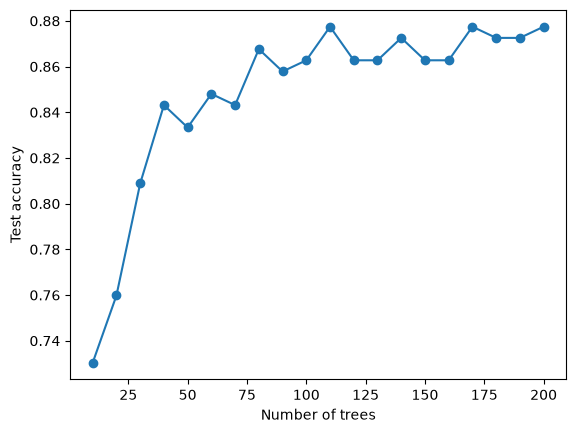

In [7]:
import matplotlib.pyplot as plt

tree_counts = range(10, 201, 10)   # 10, 20, ..., 200 (20 values)
accuracies = []

for n in tree_counts:
    rf = RandomForestClassifier(n_estimators=n, random_state=0)
    rf.fit(X_train, y_train)
    accuracies.append(accuracy_score(y_test, rf.predict(X_test)))

plt.plot(tree_counts, accuracies, marker="o")
plt.xlabel("Number of trees")
plt.ylabel("Test accuracy")
plt.show()

3. If we had picked the amount of decision trees by taking the value with the best test accuracy from the last plot, we would have *overfit* our hyperparameters to the test data. Can you see why it is a mistake to tune hyperparameters of your model by using the test data?

Yes, because the test data influences the choice of the number of trees. Picking the number of trees with the best test score picks the 'luckiest' result so the reported accuracy is going to be overly optimistic and would not reflect the performance of the model on new data.

4. Reshuffle and resplit the data so that it is divided in 3 parts: training (80%), validation (10%) and test (10%). Repeatedly train a model of your choosing (e.g random forest) on the training data, and evaluate it’s performance on the validation set, while tuning the hyperparameters so that the accuracy on the validation set increases. Then, finally evaluate the performance of your model on the test data. What can you say in terms of the generalization of your model?

In [8]:
np.random.seed(0)
idx = np.random.permutation(len(X))
X, y = X[idx], y[idx]

train_end = int(0.8 * len(X))
val_end = int(0.9 * len(X))

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]

best_acc, best_params = 0, None
for n_trees in [50, 100, 200]:
    for max_feat in ["sqrt", "log2", 0.2]:
        rf = RandomForestClassifier(n_estimators=n_trees, max_features=max_feat, random_state=0)
        rf.fit(X_train, y_train)
        acc = accuracy_score(y_val, rf.predict(X_val))
        print(n_trees, max_feat, acc)
        if acc > best_acc:
            best_acc, best_params = acc, (n_trees, max_feat)

print("Best:", best_params, "validation accuracy:", best_acc)

final = RandomForestClassifier(n_estimators=best_params[0], max_features=best_params[1], random_state=0)
final.fit(X_train, y_train)
print("Test accuracy:", accuracy_score(y_test, final.predict(X_test)))

#The best model (100 trees, max_features="sqrt") reached 87.3% validation accuracy and 88.2% on the held-out test set.
#The two scores are very close, so tuning on the validation set did not overfit and the model generalizes well to unseen data.
#Given the small set sizes, differences of 1-2% are within noise.

50 sqrt 0.7254901960784313
50 log2 0.803921568627451
50 0.2 0.7156862745098039
100 sqrt 0.7450980392156863
100 log2 0.7941176470588235
100 0.2 0.7450980392156863
200 sqrt 0.7352941176470589
200 log2 0.803921568627451
200 0.2 0.7352941176470589
Best: (50, 'log2') validation accuracy: 0.803921568627451
Test accuracy: 0.8137254901960784


**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 3 | TPOT

The process of picking a suitable model, evaluating its performance and tuning the hyperparameters is very time consuming. A new idea in machine learning is the concept of automating this by using an optimization algorithm to find the best model in the space of models and their hyperparameters. Have a look at [TPOT](https://github.com/EpistasisLab/tpot), an automated ML solution that finds a good model and a good set of hyperparameters automatically. Try it on this data, it should outperform simple models like the ones we tried easily. Note that running the algorithm might take a while, depending on the strength of your computer. 

*Note*: In case it is running for too long, try checking if the parameters you are using when calling TPOT are reasonable, i.e. try reducing number of ‘generations’ or ‘population_size’. TPOT uses cross-validation internally, so we don’t need our own validation set.

In [12]:

from tpot import TPOTClassifier

idx = np.random.permutation(len(X))
X, y = X[idx], y[idx]
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

tpot = TPOTClassifier(generations=5, population_size=20, cv=5,
                      random_state=0, n_jobs=1, verbose=2)
tpot.fit(X_train, y_train)

print("Test accuracy:", tpot.score(X_test, y_test))
print(tpot.fitted_pipeline_)

C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tpot\tpot_estimator\estimator.py:458: UserWarning: Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.
  warnings.warn("Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.")
C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\distributed\node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 49999 instead
  warnings.warn(
C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tpot\tpot_estimator\estimator.py:537: UserWarning: Labels are not encoded as ints from 0 to N. For compatibility with some classifiers such as sklea

AttributeError: 'TPOTClassifier' object has no attribute 'score'

In [14]:
pred = tpot.predict(X_test)
pred = tpot.label_encoder_.inverse_transform(pred)
print("Test accuracy:", accuracy_score(y_test, pred))

Test accuracy: 0.7892156862745098


**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**